
Cylindrical Cavity Resonant Frequencies
Radius : 46.83 mm
Height : 35.00 mm

Mode         Frequency [GHz]
------------------------------
TM_010                 2.450
TM_110                 3.904
TE_101                 4.283
TE_111                 4.676
TM_011                 4.934
TM_210                 5.232
TE_201                 5.294
TE_211                 5.294
TM_020                 5.624
TM_111                 5.795
TE_011                 5.795
TM_211                 6.761
TE_121                 6.917
TM_021                 7.069
TM_120                 7.147
TE_221                 8.064
TM_121                 8.332
TE_021                 8.332
TE_102                 8.565
TM_220                 8.575
TE_112                 8.768
TM_012                 8.909
TE_202                 9.113
TE_212                 9.113
TM_112                 9.413
TE_012                 9.413
TM_221                 9.585
TM_212                10.037
TE_122                10.143
TM_022               

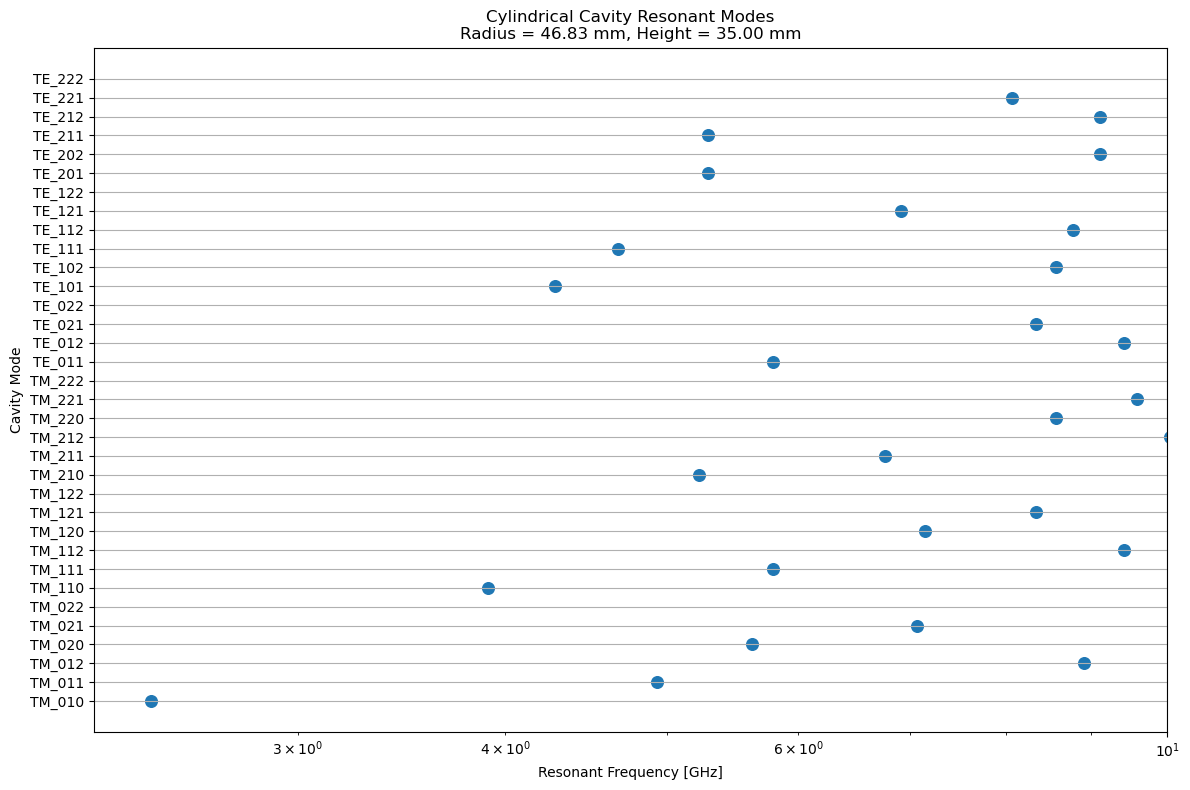

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# =============================================================================
# CONSTANTS
# =============================================================================

c = 299792458  # Speed of light [m/s]


# =============================================================================
# BESSEL FUNCTION ROOTS
# =============================================================================
#
# TM modes:
#
#     J_m(x_mn) = 0
#
# TE modes:
#
#     J'_m(x'_mn) = 0
#
# The dictionaries contain ONLY physically meaningful radial roots.
#
# -----------------------------------------------------------------------------
#
# TM:
#
#   m = 0, n = 1 -> TM_01...
#   m = 1, n = 1 -> TM_11...
#   m = 2, n = 1 -> TM_21...
#
# There is NO n = 0 TM mode.
#
# -----------------------------------------------------------------------------
#
# TE:
#
#   m = 0, n = 1 -> TE_01...
#   m = 1, n = 0 -> TE_10...
#   m = 1, n = 1 -> TE_11...
#   m = 2, n = 0 -> TE_20...
#   etc.
#
# The m=n=0 combination is invalid.
#
# =============================================================================


# -----------------------------------------------------------------------------
# TM: zeros of J_m
# -----------------------------------------------------------------------------

bessel_zeros_TM = {

    0: {
        1: 2.4048,
        2: 5.5201,
    },

    1: {
        1: 3.8317,
        2: 7.0156,
    },

    2: {
        1: 5.1356,
        2: 8.4172,
    },
}


# -----------------------------------------------------------------------------
# TE: zeros of J'_m
# -----------------------------------------------------------------------------

bessel_zeros_TE = {

    0: {
        1: 3.8317,
        2: 7.0156,
    },

    1: {
        0: 0.0,
        1: 1.8412,
        2: 5.3314,
    },

    2: {
        0: 3.0542,
        1: 3.0542,
        2: 6.7061,
    },
}


# =============================================================================
# MODE VALIDITY
# =============================================================================

def mode_is_valid(mode_type, m, n, l):

    # -------------------------------------------------------------------------
    # m = n = 0 is not a valid electromagnetic cavity mode
    # -------------------------------------------------------------------------

    if m == 0 and n == 0:
        return False

    # -------------------------------------------------------------------------
    # TM modes require n >= 1
    # -------------------------------------------------------------------------

    if mode_type == "TM" and n == 0:
        return False

    # -------------------------------------------------------------------------
    # TE modes require l >= 1 for a conventional cavity mode
    # -------------------------------------------------------------------------

    if mode_type == "TE" and l == 0:
        return False

    return True


# =============================================================================
# MODE DEFINITIONS
# =============================================================================
#
# Generate all combinations:
#
#     m = {0, 1, 2}
#     n = {0, 1, 2}
#     l = {0, 1, 2}
#
# Invalid modes are retained but marked as invalid.
#
# =============================================================================

modes = {}


for mode_type in ["TM", "TE"]:

    for m in [0, 1, 2]:

        for n in [0, 1, 2]:

            for l in [0, 1, 2]:

                mode_name = f"{mode_type}_{m}{n}{l}"

                valid = mode_is_valid(
                    mode_type,
                    m,
                    n,
                    l
                )

                modes[mode_name] = {
                    "type": mode_type,
                    "m": m,
                    "n": n,
                    "l": l,
                    "valid": valid
                }


# =============================================================================
# CAVITY DIMENSIONS
# =============================================================================

radius = float(input("Cavity radius a [mm]: "))*1e-3   # Cavity radius [m]
height = float(input("Cavity height d [mm]: "))*1e-3      # Cavity height [m]


# =============================================================================
# RESONANT FREQUENCY
# =============================================================================

def resonant_frequency(mode, radius, height):

    mode_type = mode["type"]

    m = mode["m"]
    n = mode["n"]
    l = mode["l"]

    # Invalid mode
    if not mode["valid"]:
        return np.nan

    # -------------------------------------------------------------------------
    # Select Bessel root
    # -------------------------------------------------------------------------

    if mode_type == "TM":

        if m not in bessel_zeros_TM:
            return np.nan

        if n not in bessel_zeros_TM[m]:
            return np.nan

        bessel_root = bessel_zeros_TM[m][n]

    elif mode_type == "TE":

        if m not in bessel_zeros_TE:
            return np.nan

        if n not in bessel_zeros_TE[m]:
            return np.nan

        bessel_root = bessel_zeros_TE[m][n]

    else:

        raise ValueError(
            "Mode type must be either 'TE' or 'TM'."
        )

    # -------------------------------------------------------------------------
    # Resonance equation
    # -------------------------------------------------------------------------

    radial_term = (bessel_root / radius) ** 2

    axial_term = (l * np.pi / height) ** 2

    frequency = (
        c / (2 * np.pi)
        * np.sqrt(
            radial_term + axial_term
        )
    )

    return frequency


# =============================================================================
# CALCULATE FREQUENCIES
# =============================================================================

frequencies = {}

for mode_name, mode in modes.items():

    frequencies[mode_name] = resonant_frequency(
        mode,
        radius,
        height
    )


# =============================================================================
# PRINT RESULTS
# =============================================================================

print()
print("Cylindrical Cavity Resonant Frequencies")
print("=======================================")

print(f"Radius : {radius * 1e3:.2f} mm")
print(f"Height : {height * 1e3:.2f} mm")

print()
print(
    f"{'Mode':<10}"
    f"{'Frequency [GHz]':>18}"
)

print("-" * 30)


for mode_name, frequency in sorted(
    frequencies.items(),
    key=lambda x: (
        np.inf if np.isnan(x[1]) else x[1]
    )
):

    if np.isnan(frequency):
        continue

    print(
        f"{mode_name:<10}"
        f"{frequency / 1e9:>18.3f}"
    )


# =============================================================================
# PREPARE PLOT DATA
# =============================================================================

valid_modes = {
    mode_name: frequency
    for mode_name, frequency in frequencies.items()
    if not np.isnan(frequency)
}


mode_names = list(valid_modes.keys())

frequency_GHz = np.array([
    frequency / 1e9
    for frequency in valid_modes.values()
])


# =============================================================================
# PLOT
# =============================================================================

plt.figure(figsize=(12, 8))

plt.scatter(
    frequency_GHz,
    mode_names,
    s=70
)

plt.xlabel("Resonant Frequency [GHz]")
plt.ylabel("Cavity Mode")
plt.xscale('log')
plt.xlim(right=10)

plt.title(
    "Cylindrical Cavity Resonant Modes\n"
    f"Radius = {radius * 1e3:.2f} mm, "
    f"Height = {height * 1e3:.2f} mm"
)

plt.grid(True)

plt.tight_layout()

plt.show()


CYLINDRICAL CAVITY DESIGN

Target mode       : TM_110
Target frequency  : 2.4500 GHz

Optimal geometry
----------------
Height / Radius   : 0.2000
Radius            : 74.622 mm
Height            : 14.924 mm

Mode isolation
--------------
Nearest competing mode : TM_210
Frequency separation    : 833.72 MHz

Degenerate modes
----------------
None


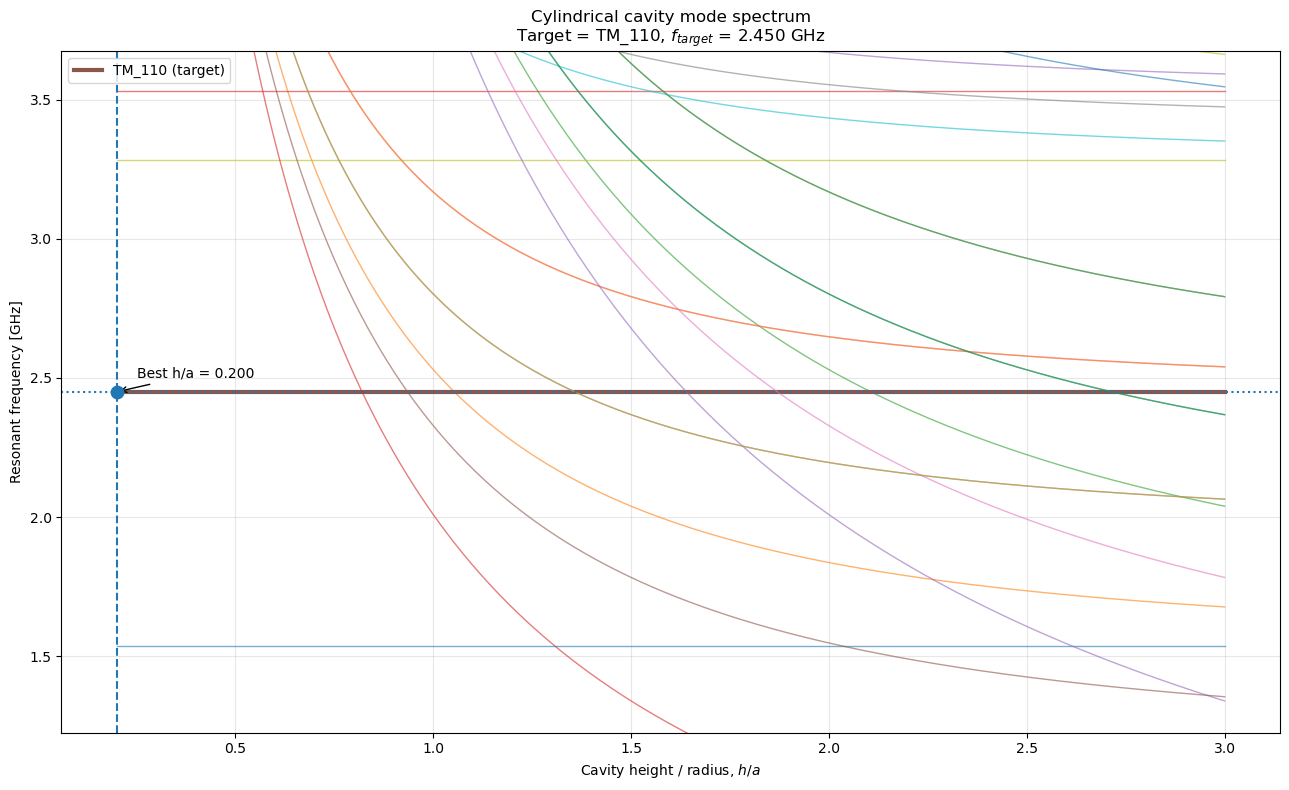

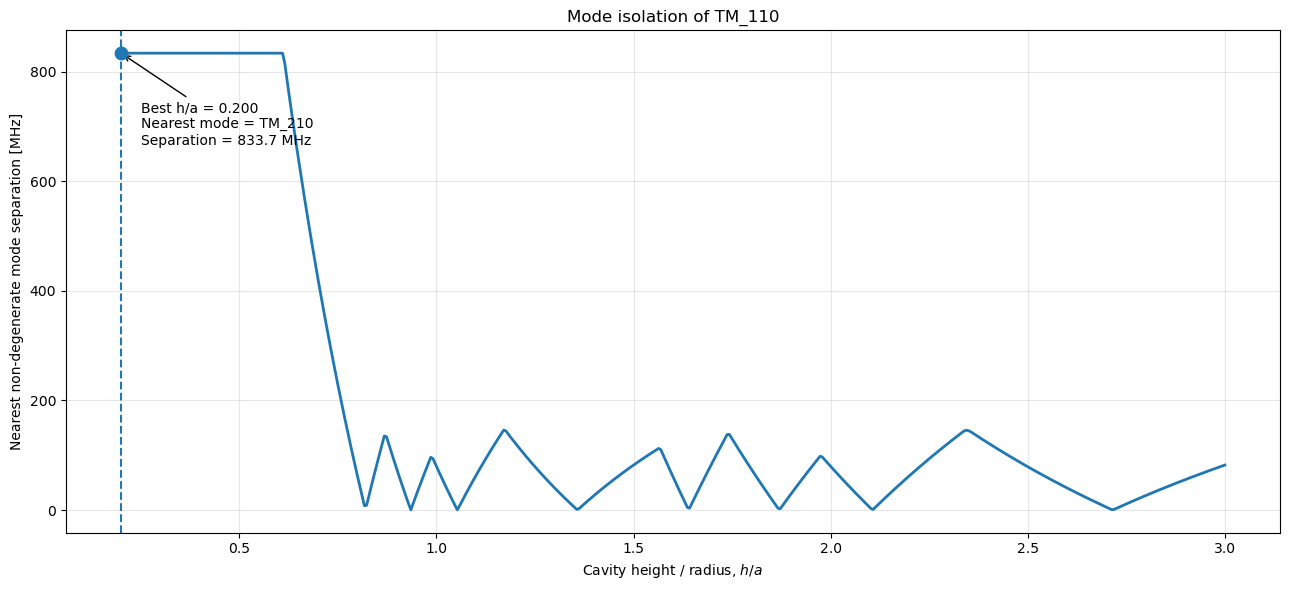

In [2]:
# =============================================================================
# CYLINDRICAL CAVITY DESIGN TOOL
# =============================================================================
#
# This cell uses the previously defined:
#
#     c
#     modes
#     bessel_zeros_TM
#     bessel_zeros_TE
#
# to investigate how the cavity aspect ratio
#
#     height / radius
#
# affects the resonant-mode spectrum.
#
# The target mode is kept at a fixed target frequency by adjusting
# the absolute cavity dimensions.
#
# =============================================================================


# =============================================================================
# USER DESIGN PARAMETERS
# =============================================================================

target_mode_name = "TM_110"

target_frequency = 2.45e9       # Target frequency [Hz]

# Range of height/radius ratios to investigate
height_radius_values = np.linspace(
    0.2,
    3.0,
    500
)

# Frequency range shown around target
plot_bandwidth = 0.50           # ±50%

# Maximum number of modes to consider
# (Your current modes dictionary contains m,n,l = 0,1,2)
# so this is controlled by the dictionary already defined.


# =============================================================================
# RESONANT FREQUENCY
# =============================================================================

def cylindrical_resonant_frequency(
        mode,
        radius,
        height
    ):

    if not mode["valid"]:
        return np.nan

    mode_type = mode["type"]

    m = mode["m"]
    n = mode["n"]
    l = mode["l"]

    # ---------------------------------------------------------
    # Select Bessel root
    # ---------------------------------------------------------

    if mode_type == "TM":

        if m not in bessel_zeros_TM:
            return np.nan

        if n not in bessel_zeros_TM[m]:
            return np.nan

        bessel_root = bessel_zeros_TM[m][n]

    elif mode_type == "TE":

        if m not in bessel_zeros_TE:
            return np.nan

        if n not in bessel_zeros_TE[m]:
            return np.nan

        bessel_root = bessel_zeros_TE[m][n]

    else:

        raise ValueError(
            "Mode type must be either TE or TM."
        )

    # ---------------------------------------------------------
    # Resonant frequency
    # ---------------------------------------------------------

    radial_term = (bessel_root / radius)**2

    axial_term = (l * np.pi / height)**2

    frequency = (
        c / (2 * np.pi)
        * np.sqrt(
            radial_term + axial_term
        )
    )

    return frequency


# =============================================================================
# CALCULATE RADIUS REQUIRED FOR TARGET FREQUENCY
# =============================================================================

def calculate_radius_for_target_frequency(
        mode,
        target_frequency,
        height_radius_ratio
    ):

    if not mode["valid"]:
        return np.nan

    mode_type = mode["type"]

    m = mode["m"]
    n = mode["n"]
    l = mode["l"]

    # ---------------------------------------------------------
    # Select Bessel root
    # ---------------------------------------------------------

    if mode_type == "TM":

        if m not in bessel_zeros_TM:
            return np.nan

        if n not in bessel_zeros_TM[m]:
            return np.nan

        bessel_root = bessel_zeros_TM[m][n]

    elif mode_type == "TE":

        if m not in bessel_zeros_TE:
            return np.nan

        if n not in bessel_zeros_TE[m]:
            return np.nan

        bessel_root = bessel_zeros_TE[m][n]

    else:

        raise ValueError(
            "Mode type must be either TE or TM."
        )

    # ---------------------------------------------------------
    # Solve analytically for radius
    #
    # h = ratio * radius
    #
    # f = c/(2πr) *
    #     sqrt(x^2 + (lπ/ratio)^2)
    #
    # ---------------------------------------------------------

    radius = (
        c
        / (2 * np.pi * target_frequency)
        * np.sqrt(
            bessel_root**2
            +
            (l * np.pi / height_radius_ratio)**2
        )
    )

    return radius


# =============================================================================
# TARGET MODE
# =============================================================================

if target_mode_name not in modes:

    raise ValueError(
        f"{target_mode_name} is not present in the modes dictionary."
    )

target_mode = modes[target_mode_name]

if not target_mode["valid"]:

    raise ValueError(
        f"{target_mode_name} is not a valid cavity mode."
    )


# =============================================================================
# CALCULATE MODE FREQUENCY CURVES
# =============================================================================

frequency_curves = {
    mode_name: []
    for mode_name in modes
}


radius_curves = []
height_curves = []


for ratio in height_radius_values:

    # ---------------------------------------------------------
    # Find radius which places TARGET MODE at target frequency
    # ---------------------------------------------------------

    radius = calculate_radius_for_target_frequency(
        target_mode,
        target_frequency,
        ratio
    )

    height = ratio * radius

    radius_curves.append(radius)
    height_curves.append(height)

    # ---------------------------------------------------------
    # Calculate every mode at this geometry
    # ---------------------------------------------------------

    for mode_name, mode in modes.items():

        frequency = cylindrical_resonant_frequency(
            mode,
            radius,
            height
        )

        frequency_curves[mode_name].append(
            frequency / 1e9
        )


# Convert lists to arrays

for mode_name in frequency_curves:

    frequency_curves[mode_name] = np.array(
        frequency_curves[mode_name]
    )

radius_curves = np.array(radius_curves)
height_curves = np.array(height_curves)


# =============================================================================
# IDENTIFY DEGENERATE MODES
# =============================================================================
#
# A mode is considered degenerate with the target if its frequency
# curve is identical to the target frequency curve.
#
# This is useful because we don't want to treat a deliberately
# degenerate mode as a competing mode.
#
# =============================================================================

target_curve = frequency_curves[target_mode_name]

degenerate_modes = []

for mode_name, curve in frequency_curves.items():

    if mode_name == target_mode_name:
        continue

    if np.allclose(
        curve,
        target_curve,
        rtol=1e-10,
        atol=1e-10
    ):

        degenerate_modes.append(mode_name)


# =============================================================================
# FIND CLOSEST NON-DEGENERATE MODE
# =============================================================================

closest_mode = []
closest_separation = []


for i in range(len(height_radius_values)):

    target_frequency_at_point = target_curve[i]

    best_separation = np.inf
    best_mode = None

    for mode_name, curve in frequency_curves.items():

        # Ignore target and its degenerate partners
        if (
            mode_name == target_mode_name
            or mode_name in degenerate_modes
        ):
            continue

        frequency_difference = abs(
            curve[i] - target_frequency_at_point
        )

        if frequency_difference < best_separation:

            best_separation = frequency_difference
            best_mode = mode_name

    closest_mode.append(best_mode)
    closest_separation.append(best_separation)


closest_separation = np.array(
    closest_separation
)


# =============================================================================
# FIND OPTIMAL HEIGHT/RADIUS RATIO
# =============================================================================

best_index = np.argmax(
    closest_separation
)

best_height_radius = height_radius_values[
    best_index
]

best_separation = closest_separation[
    best_index
]

best_neighbour = closest_mode[
    best_index
]


# =============================================================================
# CALCULATE OPTIMAL DIMENSIONS
# =============================================================================

best_radius = calculate_radius_for_target_frequency(
    target_mode,
    target_frequency,
    best_height_radius
)

best_height = (
    best_height_radius
    * best_radius
)


# =============================================================================
# PRINT DESIGN RESULTS
# =============================================================================

print()
print("=" * 55)
print("CYLINDRICAL CAVITY DESIGN")
print("=" * 55)

print()
print(f"Target mode       : {target_mode_name}")
print(
    f"Target frequency  : "
    f"{target_frequency / 1e9:.4f} GHz"
)

print()
print("Optimal geometry")
print("----------------")

print(
    f"Height / Radius   : "
    f"{best_height_radius:.4f}"
)

print(
    f"Radius            : "
    f"{best_radius * 1e3:.3f} mm"
)

print(
    f"Height            : "
    f"{best_height * 1e3:.3f} mm"
)

print()
print("Mode isolation")
print("--------------")

print(
    f"Nearest competing mode : "
    f"{best_neighbour}"
)

print(
    f"Frequency separation    : "
    f"{best_separation * 1e3:.2f} MHz"
)

print()
print("Degenerate modes")
print("----------------")

if len(degenerate_modes) == 0:

    print("None")

else:

    for mode_name in degenerate_modes:

        print(mode_name)


# =============================================================================
# PLOT 1 — MODE SPECTRUM
# =============================================================================

fig, ax = plt.subplots(
    figsize=(13, 8)
)


# ---------------------------------------------------------
# Frequency limits
# ---------------------------------------------------------

lower_frequency = (
    target_frequency
    / 1e9
    * (1 - plot_bandwidth)
)

upper_frequency = (
    target_frequency
    / 1e9
    * (1 + plot_bandwidth)
)


# ---------------------------------------------------------
# Plot modes
# ---------------------------------------------------------

for mode_name, curve in frequency_curves.items():

    visible = (
        (curve >= lower_frequency)
        &
        (curve <= upper_frequency)
    )

    if not np.any(visible):
        continue

    # Target mode
    if mode_name == target_mode_name:

        ax.plot(
            height_radius_values,
            curve,
            linewidth=3,
            label=f"{mode_name} (target)"
        )

    # Degenerate modes
    elif mode_name in degenerate_modes:

        ax.plot(
            height_radius_values,
            curve,
            linewidth=2,
            linestyle="--",
            label=f"{mode_name} (degenerate)"
        )

    # Other modes
    else:

        ax.plot(
            height_radius_values,
            curve,
            linewidth=1,
            alpha=0.6
        )


# ---------------------------------------------------------
# Mark optimum
# ---------------------------------------------------------

ax.axvline(
    best_height_radius,
    linestyle="--",
    linewidth=1.5
)

ax.axhline(
    target_frequency / 1e9,
    linestyle=":",
    linewidth=1.5
)

ax.scatter(
    best_height_radius,
    target_frequency / 1e9,
    s=80,
    zorder=5
)

ax.annotate(
    f"Best h/a = {best_height_radius:.3f}",
    xy=(
        best_height_radius,
        target_frequency / 1e9
    ),
    xytext=(
        best_height_radius + 0.05,
        target_frequency / 1e9 + 0.05
    ),
    arrowprops=dict(
        arrowstyle="->"
    )
)


# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------

ax.set_xlabel(
    r"Cavity height / radius, $h/a$"
)

ax.set_ylabel(
    "Resonant frequency [GHz]"
)

ax.set_title(
    f"Cylindrical cavity mode spectrum\n"
    f"Target = {target_mode_name}, "
    f"$f_{{target}}$ = "
    f"{target_frequency / 1e9:.3f} GHz"
)

ax.set_ylim(
    lower_frequency,
    upper_frequency
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()
plt.show()


# =============================================================================
# PLOT 2 — MODE ISOLATION
# =============================================================================

fig, ax = plt.subplots(
    figsize=(13, 6)
)

ax.plot(
    height_radius_values,
    closest_separation * 1000,
    linewidth=2
)

ax.axvline(
    best_height_radius,
    linestyle="--",
    linewidth=1.5
)

ax.scatter(
    best_height_radius,
    best_separation * 1000,
    s=80,
    zorder=5
)

ax.annotate(
    f"Best h/a = {best_height_radius:.3f}\n"
    f"Nearest mode = {best_neighbour}\n"
    f"Separation = {best_separation * 1000:.1f} MHz",
    xy=(
        best_height_radius,
        best_separation * 1000
    ),
    xytext=(
        best_height_radius + 0.05,
        best_separation * 1000 * 0.8
    ),
    arrowprops=dict(
        arrowstyle="->"
    )
)

ax.set_xlabel(
    r"Cavity height / radius, $h/a$"
)

ax.set_ylabel(
    "Nearest non-degenerate mode separation [MHz]"
)

ax.set_title(
    f"Mode isolation of {target_mode_name}"
)

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()


Target mode:
    210

Degenerate modes:
    120

OPTIMUM CAVITY
Target mode:        210
Target frequency:   2.4500 GHz

Best c/a:           0.2000

a = 136.807 mm
b = 136.807 mm
c = 27.361 mm

Nearest non-degenerate mode: 020
Mode separation: 258.65 MHz


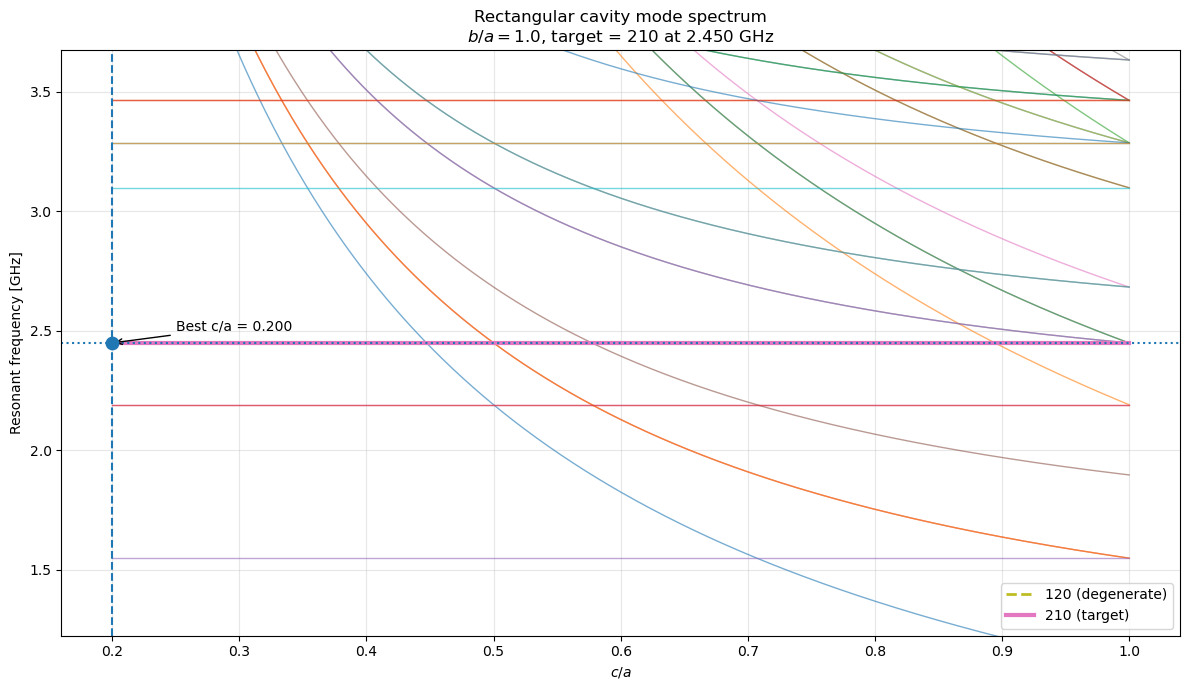

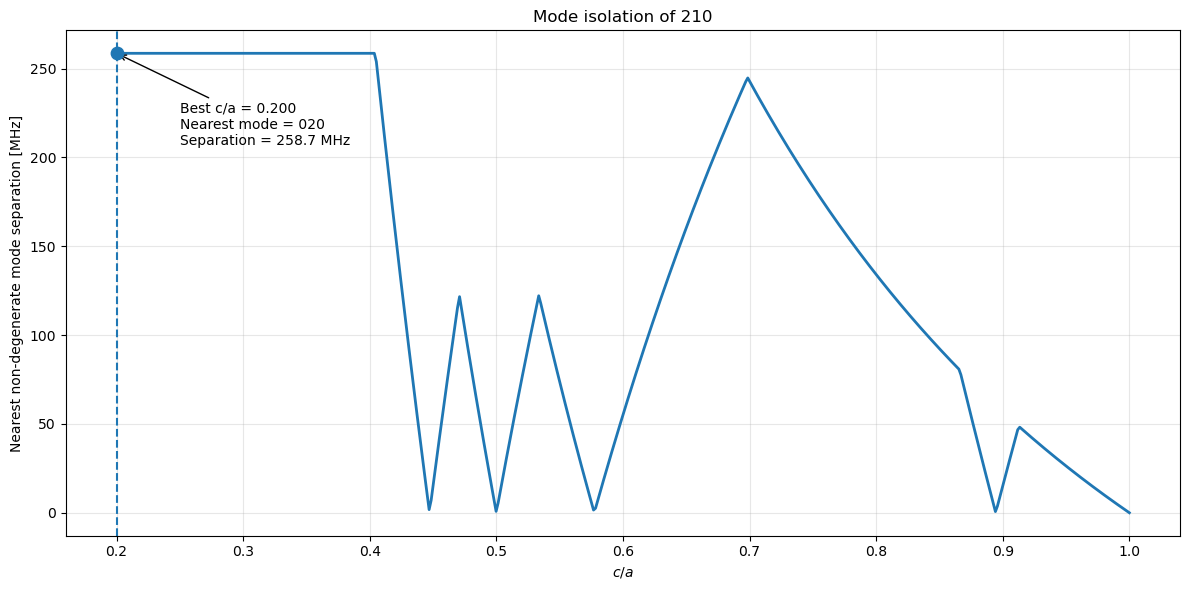

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONSTANTS
# ============================================================

c0 = 299792458  # speed of light [m/s]

# ============================================================
# USER DESIGN PARAMETERS
# ============================================================

target_mode_name = "210"
target_frequency = 2.45e9       # Hz

b_a_ratio = 1.0                 # Fixed: b = a

# Range of c/a values to investigate
c_a_values = np.linspace(0.2, 1, 500)

# Maximum mode indices to consider
max_mode = 4

# Frequency window around target to display
plot_bandwidth = 0.50           # ±50% of target frequency


# ============================================================
# GENERATE MODES
# ============================================================

modes = {}

for m in range(max_mode + 1):
    for n in range(max_mode + 1):
        for l in range(max_mode + 1):

            # 000 is not a physical cavity mode
            if m == 0 and n == 0 and l == 0:
                continue

            mode_name = f"{m}{n}{l}"

            modes[mode_name] = {
                "m": m,
                "n": n,
                "l": l
            }


# ============================================================
# FREQUENCY CALCULATIONS
# ============================================================

def calculate_a(mode, frequency, b_a_ratio, c_a_ratio):

    m = mode["m"]
    n = mode["n"]
    l = mode["l"]

    dimensionless_term = np.sqrt(
        m**2
        + n**2 / b_a_ratio**2
        + l**2 / c_a_ratio**2
    )

    return (
        c0 / (2 * frequency)
    ) * dimensionless_term


def resonant_frequency(mode, a, b, c):

    m = mode["m"]
    n = mode["n"]
    l = mode["l"]

    return (
        c0 / 2
    ) * np.sqrt(
        (m / a)**2
        + (n / b)**2
        + (l / c)**2
    )


# ============================================================
# CALCULATE ALL MODE CURVES
# ============================================================

frequency_curves = {
    mode_name: []
    for mode_name in modes
}

for c_a_ratio in c_a_values:

    # Keep the target mode at the target frequency
    target_mode = modes[target_mode_name]

    a = calculate_a(
        target_mode,
        target_frequency,
        b_a_ratio,
        c_a_ratio
    )

    b = b_a_ratio * a
    c = c_a_ratio * a

    for mode_name, mode in modes.items():

        frequency = resonant_frequency(
            mode,
            a,
            b,
            c
        )

        frequency_curves[mode_name].append(
            frequency / 1e9
        )


# Convert to numpy arrays
for mode_name in frequency_curves:
    frequency_curves[mode_name] = np.array(
        frequency_curves[mode_name]
    )


# ============================================================
# FIND DEGENERATE MODES
# ============================================================

# Modes which are mathematically identical to target
# for b/a = 1.

target_curve = frequency_curves[target_mode_name]

degenerate_modes = []

for mode_name, curve in frequency_curves.items():

    if mode_name == target_mode_name:
        continue

    if np.allclose(curve, target_curve, atol=1e-10):
        degenerate_modes.append(mode_name)


print("\nTarget mode:")
print(f"    {target_mode_name}")

print("\nDegenerate modes:")
for mode in degenerate_modes:
    print(f"    {mode}")


# ============================================================
# FIND CLOSEST NON-DEGENERATE MODE
# ============================================================

closest_mode = []
closest_separation = []

for i in range(len(c_a_values)):

    target_f = target_curve[i]

    best_separation = np.inf
    best_mode = None

    for mode_name, curve in frequency_curves.items():

        # Ignore target and degenerate partners
        if (
            mode_name == target_mode_name
            or mode_name in degenerate_modes
        ):
            continue

        separation = abs(
            curve[i] - target_f
        )

        if separation < best_separation:

            best_separation = separation
            best_mode = mode_name

    closest_mode.append(best_mode)
    closest_separation.append(best_separation)


closest_separation = np.array(
    closest_separation
)


# ============================================================
# FIND BEST c/a
# ============================================================

best_index = np.argmax(
    closest_separation
)

best_c_a = c_a_values[best_index]

best_separation = closest_separation[
    best_index
]

best_neighbour = closest_mode[
    best_index
]


# Calculate cavity dimensions at optimum
best_a = calculate_a(
    target_mode,
    target_frequency,
    b_a_ratio,
    best_c_a
)

best_b = b_a_ratio * best_a
best_c = best_c_a * best_a


# ============================================================
# PRINT DESIGN
# ============================================================

print("\n==============================")
print("OPTIMUM CAVITY")
print("==============================")

print(f"Target mode:        {target_mode_name}")
print(f"Target frequency:   {target_frequency/1e9:.4f} GHz")

print(f"\nBest c/a:           {best_c_a:.4f}")

print(f"\na = {best_a*1000:.3f} mm")
print(f"b = {best_b*1000:.3f} mm")
print(f"c = {best_c*1000:.3f} mm")

print(
    f"\nNearest non-degenerate mode: "
    f"{best_neighbour}"
)

print(
    f"Mode separation: "
    f"{best_separation*1000:.2f} MHz"
)


# ============================================================
# PLOT 1 — MODE SPECTRUM
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

# Determine sensible frequency limits
lower_frequency = target_frequency / 1e9 * (1 - plot_bandwidth)
upper_frequency = target_frequency / 1e9 * (1 + plot_bandwidth)


for mode_name, curve in frequency_curves.items():

    # Only plot modes which enter our frequency window
    visible = (
        (curve >= lower_frequency)
        &
        (curve <= upper_frequency)
    )

    if not np.any(visible):
        continue

    # --------------------------------------------------------
    # TARGET MODE
    # --------------------------------------------------------

    if mode_name == target_mode_name:

        ax.plot(
            c_a_values,
            curve,
            linewidth=3,
            label=f"{mode_name} (target)"
        )

    # --------------------------------------------------------
    # DEGENERATE MODES
    # Always show these so that the degeneracy is visible
    # --------------------------------------------------------

    elif mode_name in degenerate_modes:

        ax.plot(
            c_a_values,
            curve,
            linewidth=2,
            linestyle="--",
            label=f"{mode_name} (degenerate)"
        )

    # --------------------------------------------------------
    # OTHER MODES
    # --------------------------------------------------------

    else:

        ax.plot(
            c_a_values,
            curve,
            linewidth=1,
            alpha=0.6
        )


# Mark optimum c/a
ax.axvline(
    best_c_a,
    linestyle="--",
    linewidth=1.5
)

# Mark target frequency
ax.axhline(
    target_frequency / 1e9,
    linestyle=":",
    linewidth=1.5
)

# Mark optimum point
ax.scatter(
    best_c_a,
    target_frequency / 1e9,
    s=80,
    zorder=5
)

ax.annotate(
    f"Best c/a = {best_c_a:.3f}",
    xy=(
        best_c_a,
        target_frequency / 1e9
    ),
    xytext=(
        best_c_a + 0.05,
        target_frequency / 1e9 + 0.05
    ),
    arrowprops=dict(
        arrowstyle="->"
    )
)


ax.set_xlabel(r"$c/a$")
ax.set_ylabel("Resonant frequency [GHz]")

ax.set_title(
    f"Rectangular cavity mode spectrum\n"
    f"$b/a = {b_a_ratio}$, "
    f"target = {target_mode_name} "
    f"at {target_frequency/1e9:.3f} GHz"
)

ax.set_ylim(
    lower_frequency,
    upper_frequency
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2 — MODE ISOLATION
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.plot(
    c_a_values,
    closest_separation * 1000,
    linewidth=2
)

ax.axvline(
    best_c_a,
    linestyle="--",
    linewidth=1.5
)

ax.scatter(
    best_c_a,
    best_separation * 1000,
    s=80,
    zorder=5
)

ax.annotate(
    f"Best c/a = {best_c_a:.3f}\n"
    f"Nearest mode = {best_neighbour}\n"
    f"Separation = {best_separation*1000:.1f} MHz",
    xy=(
        best_c_a,
        best_separation * 1000
    ),
    xytext=(
        best_c_a + 0.05,
        best_separation * 1000 * 0.8
    ),
    arrowprops=dict(
        arrowstyle="->"
    )
)

ax.set_xlabel(r"$c/a$")
ax.set_ylabel("Nearest non-degenerate mode separation [MHz]")

ax.set_title(
    f"Mode isolation of {target_mode_name}"
)

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Quality Factor')

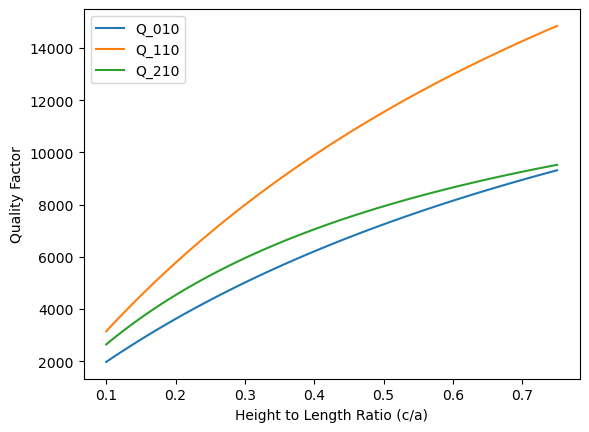

In [4]:
#Quality Fcator considerations

a_010 = 46.833*1e-3
a_110 = 74.622*1e-3
a_210 = 136.807*1e-3
height_ratio = np.linspace(0.1, 0.75, 100)
sigma_Al = 3.5*1e7
mu0 = 4*np.pi*1e-7
omega = 2.45*1e9
constant = np.sqrt(2*omega*sigma_Al*mu0)

Q_110 = a_110*constant*height_ratio/(1+height_ratio)
Q_010 = a_010*constant*height_ratio/(1+height_ratio)
Q_210 = a_210*constant*height_ratio/(2*(1+2*height_ratio))

plt.plot(height_ratio, Q_010, label='Q_010')
plt.plot(height_ratio, Q_110, label='Q_110')
plt.plot(height_ratio, Q_210, label='Q_210')
plt.legend()
plt.xlabel(r'Height to Length Ratio (c/a)')
plt.ylabel('Quality Factor')